# 01-7. 이론 검증 Ⅱ: 노면온도의 공간 변동과 노면상태, 정리

13장의 뒷부분(13-5 ~ 13-10)과 14장입니다. 대기 안정도, 하늘시계와 지형 차폐, 교량, 터널, 노면상태 코드, ASOS 지면온도에 관한 가설(H5~H11)을 확인하고 01 전체를 정리합니다. 01-2의 분석용 자료, 01-4의 결합 자료(`m`)와 기온감률, 01-5의 교량·터널 자료를 씁니다.

- 13-5. 대기 안정도 (H5, H6)
- 13-6. 하늘시계와 지형 차폐 (H7)
- 13-7. 교량 (H8)
- 13-8. 터널 (H9)
- 13-9. 노면상태 코드와 변수 영향 재검토 (H1, H11)
- 13-10. ASOS 지면온도는 노면온도를 대신할 수 있는가 (H10)
- 14. 정리: 주요 발견과 분석 방향

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import json
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from cycler import cycler
from matplotlib import font_manager
from scipy.spatial.distance import cdist
from scipy.stats import kruskal, spearmanr

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# 한글 글꼴 (설치된 것 중 먼저 찾은 것)
for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=PALETTE),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
ROUTE_COLORS = {"서해안": PALETTE[0], "호남선": PALETTE[1], "통영-대전중부선": PALETTE[2]}
INK, MUTED = "#0b0b0b", "#898781"
HOLDOUT = list(config.HOLDOUT_STATIONS)
CRS = 5179

In [3]:
# 01-2·01-4·01-5에서 저장한 자료
m = pd.read_parquet(config.INTERIM_DIR / "rwis_weather.parquet")  # 01-4(6-1)의 RWIS + 최근접 AWS·ASOS 결합 자료
rwis = pd.read_parquet(config.INTERIM_DIR / "rwis.parquet")
asos = pd.read_parquet(config.INTERIM_DIR / "asos.parquet")
aws = pd.read_parquet(config.INTERIM_DIR / "aws.parquet")
rwis_st = pd.read_parquet(config.INTERIM_DIR / "stations_rwis.parquet")
lapse = pd.read_parquet(config.INTERIM_DIR / "lapse_rates.parquet")  # 01-4(8장)의 시각별 기온감률
bridge_poly = gpd.read_file(config.INTERIM_DIR / "bridge_poly.gpkg")  # 01-5(11-3)
hw_tunnels = gpd.read_file(config.INTERIM_DIR / "hw_tunnels.gpkg")
centerline = gpd.read_file(config.RAW_DIR / config.RAW_FILES["centerline"])
dem_path = config.RAW_DIR / config.RAW_FILES["dem"]
dem_scale = json.load(open(config.INTERIM_DIR / "eda_meta.json", encoding="utf-8"))["dem_scale"]  # 01-2의 2-2


def to_points(df, lon="경도", lat="위도"):
    return gpd.GeoDataFrame(df.copy(), geometry=gpd.points_from_xy(df[lon], df[lat]), crs=4326).to_crs(CRS)


xy = lambda g: np.c_[g.geometry.x, g.geometry.y]

rwis_pt = to_points(rwis_st)
st_info = rwis_st.set_index("stn")

# 앞 노트북과 같은 방법으로 다시 만드는 값
aws_vars = [c for c in aws.columns[5:21]]
aws_clean = aws[aws_vars].mask(aws[aws_vars] <= -99)  # AWS 결측 코드 -99.x (01-2의 3-2)
lapse_all, lapse_np = lapse["전체"], lapse["설천봉 제외"]
W = rwis.pivot(index="time", columns="stn", values="rst")  # 관측소별 노면온도 (01-3의 4-7)
D_all = pd.DataFrame(cdist(xy(rwis_pt), xy(rwis_pt)) / 1000, index=rwis_pt["stn"], columns=rwis_pt["stn"])
EXCLUDE_AWS = [314, 300, 700, 719, 756]  # 산 정상(설천봉)·섬 AWS (01-4의 6-1)
print(m.shape)

(587445, 56)


## 13. 이론 검증 분석 (계속)

13-1 ~ 13-4는 01-6에 있습니다. 여기서도 결합 자료 `m`을 주로 쓰고 기온·습도를 직접 재는 기본·거점 관측소 9곳은 자체 센서 값을 씁니다.

### 13-5. 대기 안정도 (H5, H6)

Chapman et al.(2001)의 Pasquill–Gifford 등급을 밤 시간(19~06시)에 적용했습니다. 풍속은 섬과 산 정상을 뺀 AWS 10분 평균 풍속의 평균이고 운량은 ASOS 10개소 전운량 평균(10분위 x 0.8 = 옥타)입니다.

In [4]:
aws_ws = aws_clean["10분 평균 풍속(m/s)"].where(~aws["stn"].isin(EXCLUDE_AWS))
stab = pd.DataFrame({"풍속": aws_ws.groupby(aws["time"]).mean()})
stab["운량_옥타"] = asos.groupby("time")["전운량(10분위)"].mean().reindex(stab.index.floor("h")).to_numpy() * 0.8
ws_, ok_ = stab["풍속"], stab["운량_옥타"]
stab["안정도"] = np.select([ws_ > 5, (ws_ >= 3) & (ok_ >= 4), ws_ >= 3, (ws_ >= 2) & (ok_ >= 4), ws_ >= 2, ws_ < 2],
                         ["D", "D", "E", "E", "F", "G"], "?")
stab["밤"] = (stab.index.hour >= 19) | (stab.index.hour <= 6)
stab["감률(전체)"] = lapse_all
stab["감률(설천봉 제외)"] = lapse_np
nstab = stab[stab["밤"] & (stab["안정도"] != "?")]
night_m = m.assign(안정도=stab["안정도"].reindex(m["time"]).to_numpy())
night_m = night_m[night_m["time"].isin(nstab.index) & (night_m["rst"] < 1.5) & night_m["state"].notna()]
st_tbl = nstab.groupby("안정도").agg(밤시간_비율=("풍속", "size"), 풍속=("풍속", "median"), 운량_옥타=("운량_옥타", "median"),
                                     감률_전체=("감률(전체)", "median"), 감률_설천봉제외=("감률(설천봉 제외)", "median"))
st_tbl["밤시간_비율"] /= st_tbl["밤시간_비율"].sum()
st_tbl["Chapman 감률"] = pd.Series({"D": -0.9, "E": -0.6, "F": -0.3, "G": 0.0})
st_tbl["노면<1.5°C일 때 Ice(‰)"] = night_m.groupby("안정도")["state"].apply(lambda s: (s == 4).mean() * 1000)
st_tbl["노면<1.5°C일 때 결빙관련(%)"] = night_m.groupby("안정도")["state"].apply(lambda s: s.isin([3, 4, 13, 15]).mean() * 100)
st_tbl.round(3)

,밤시간_비율,풍속,운량_옥타,감률_전체,감률_설천봉제외,Chapman 감률,노면<1.5°C일 때 Ice(‰),노면<1.5°C일 때 결빙관련(%)
안정도,,,,,,,,
D,0.068,3.631,6.88,-0.779,-0.818,-0.9,5.425,13.808
E,0.107,2.541,6.64,-0.734,-0.785,-0.6,2.397,5.404
F,0.042,2.389,1.60,-0.761,-0.746,-0.3,0.148,0.177
G,0.783,1.003,3.44,-0.532,-0.725,0.0,0.807,1.927


등급별로 관측소 노면온도의 공간 분포를 봤습니다. 시각마다 17개소 평균을 뺀 편차를 등급별로 평균하고 표고로 설명되는 부분과 나머지(잔차)를 나눕니다.

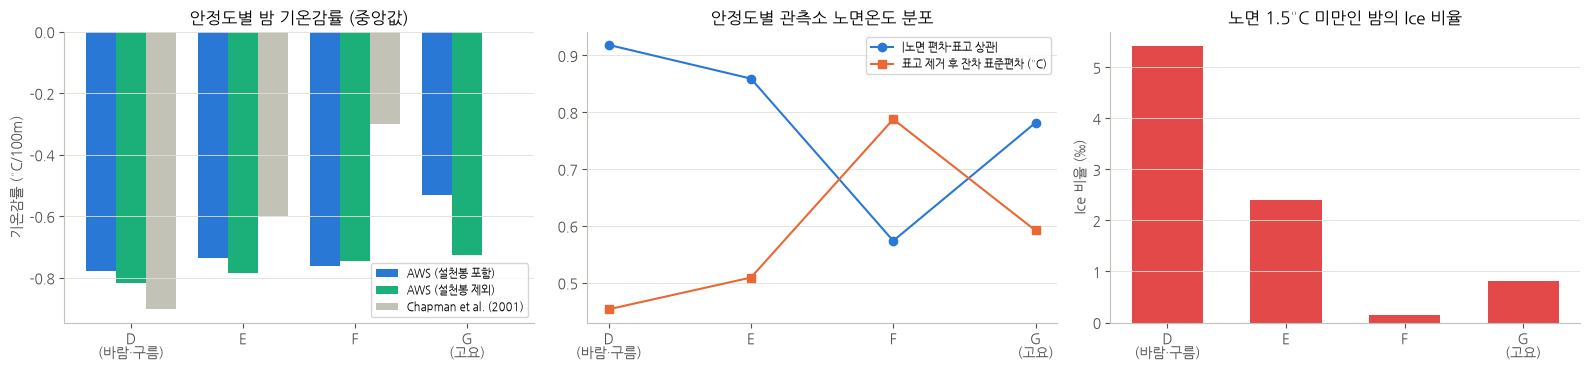

,밤 시간(h),지점 간 표준편차(중앙값),편차-표고 상관,표고 기울기(°C/100m),표고 제거 후 잔차 표준편차
안정도,,,,,
D,194.50,1.41,-0.92,-0.57,0.45
E,307.83,1.38,-0.86,-0.46,0.51
F,121.67,1.30,-0.57,-0.30,0.79
G,2256.00,1.24,-0.78,-0.40,0.59


In [5]:
elev_st = st_info["고도"].astype(float)
anom_rst = W.sub(W.mean(axis=1), axis=0)
rows, resid_by_class = [], {}
for c in ["D", "E", "F", "G"]:
    idx = nstab.index[nstab["안정도"] == c]
    a = anom_rst.reindex(idx).mean()
    coef = np.polyfit(elev_st[a.index], a, 1)
    resid_by_class[c] = a - np.polyval(coef, elev_st[a.index])
    rows.append({"안정도": c, "밤 시간(h)": len(idx) / 6, "지점 간 표준편차(중앙값)": W.reindex(idx).std(axis=1).median(),
                 "편차-표고 상관": np.corrcoef(elev_st[a.index], a)[0, 1], "표고 기울기(°C/100m)": coef[0] * 100,
                 "표고 제거 후 잔차 표준편차": resid_by_class[c].std()})
stab_rst = pd.DataFrame(rows).set_index("안정도")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
xs = np.arange(4)
axes[0].bar(xs - 0.27, st_tbl["감률_전체"], width=0.27, color=PALETTE[0], label="AWS (설천봉 포함)")
axes[0].bar(xs, st_tbl["감률_설천봉제외"], width=0.27, color=PALETTE[2], label="AWS (설천봉 제외)")
axes[0].bar(xs + 0.27, st_tbl["Chapman 감률"], width=0.27, color="#c3c2b7", label="Chapman et al. (2001)")
axes[0].set_ylabel("기온감률 (°C/100m)")
axes[0].set_title("안정도별 밤 기온감률 (중앙값)")
axes[1].plot(xs, stab_rst["편차-표고 상관"].abs(), marker="o", color=PALETTE[0], label="|노면 편차-표고 상관|")
axes[1].plot(xs, stab_rst["표고 제거 후 잔차 표준편차"], marker="s", color=PALETTE[1], label="표고 제거 후 잔차 표준편차 (°C)")
axes[1].set_title("안정도별 관측소 노면온도 분포")
axes[2].bar(xs, st_tbl["노면<1.5°C일 때 Ice(‰)"], color=PALETTE[7], width=0.6)
axes[2].set_ylabel("Ice 비율 (‰)")
axes[2].set_title("노면 1.5°C 미만인 밤의 Ice 비율")
for ax in axes:
    ax.set_xticks(xs, ["D\n(바람·구름)", "E", "F", "G\n(고요)"])
    ax.grid(axis="x", visible=False)
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
stab_rst.round(2)

밤 시간의 78%가 G(풍속 2 m/s 미만)입니다.

기온감률은 설천봉(해발 약 1,500m)을 넣으면 G에서 -0.53°C/100m로 완만해집니다. 설천봉을 빼면 모든 등급에서 -0.73~-0.82로 거의 같습니다. 산 정상만 밤 역전층 위에 있고 고속도로가 지나는 해발 20~500m에서는 감률이 거의 일정합니다. 그래서 등급별 감률(0~9°C/km)을 쓰지 않고 고정 감률(0.65°C/100m)을 씁니다(H6 부분 지지).

표고가 관측소 간 차이를 설명하는 정도는 D(상관 -0.92)에서 F(-0.57)로 약해지고 잔차는 D 0.45°C에서 F 0.79°C로 커집니다. Chapman의 결론과 같은 방향입니다. 전체 표준편차는 표고 차가 큰 D에서 가장 큽니다. 03-1의 추정 오차도 안정한 밤에 더 컸습니다(03-1의 2장).

노면이 1.5°C 미만인 밤의 Ice 비율은 D 5.4‰, E 2.4‰, F 0.15‰, G 0.8‰입니다. D는 맑고 고요한 G의 약 7배, F의 약 35배입니다. 바람이 있고 흐린 밤은 눈·비를 동반한 기압계가 지나는 밤입니다. 맑고 고요한 밤의 블랙아이스는 서리형 결빙의 설명이고 이 자료의 Ice와는 맞지 않습니다(H5).

### 13-6. 하늘시계와 지형 차폐 (H7)

DEM으로 관측소마다 72개 방위(5° 간격, 반경 5km)의 지형 수평선 고도각 h를 구하고 하늘시계 SVF = 1 - mean(sin²h)를 계산했습니다. 차폐는 동지(2024-12-22) 하루 직달 일사 중 지형에 가려지는 비율(태양고도 sin 가중)입니다.

In [6]:
def horizon_profile(x, y, max_dist=5000, n_az=72):
    """DEM으로 구한 방위별(북=0, 시계방향) 지형 수평선 고도각(도)."""
    with rasterio.open(dem_path) as src:
        r = int(max_dist / src.res[0]) + 2
        row, col = src.index(x, y)
        win = rasterio.windows.Window(col - r, row - r, 2 * r + 1, 2 * r + 1)
        z = src.read(1, window=win, boundless=True, fill_value=-9999).astype(float)
        tf = src.window_transform(win)
    z[z < -1000] = np.nan
    z *= dem_scale
    az = np.radians(np.arange(n_az) * 360 / n_az)
    dists = np.arange(30, max_dist + 30, 30)
    cc, rr = ~tf * (x + np.sin(az)[:, None] * dists, y + np.cos(az)[:, None] * dists)
    zz = z[rr.astype(int).clip(0, z.shape[0] - 1), cc.astype(int).clip(0, z.shape[1] - 1)]
    c0, r0 = ~tf * (x, y)
    ang = np.degrees(np.arctan((zz - z[int(r0), int(c0)]) / dists))
    return np.clip(np.nan_to_num(ang, nan=0).max(axis=1), 0, None)


def sun_position(times, lat, lon):
    """태양고도·방위각(도, 방위각은 북=0 시계방향). NOAA 근사식, times는 KST."""
    t = pd.DatetimeIndex(times)
    hour = t.hour.to_numpy() + t.minute.to_numpy() / 60
    g_ = 2 * np.pi / 365 * (t.dayofyear.to_numpy() - 1 + (hour - 12) / 24)
    eqt = 229.18 * (0.000075 + 0.001868 * np.cos(g_) - 0.032077 * np.sin(g_) - 0.014615 * np.cos(2 * g_)
                    - 0.040849 * np.sin(2 * g_))
    decl = (0.006918 - 0.399912 * np.cos(g_) + 0.070257 * np.sin(g_) - 0.006758 * np.cos(2 * g_)
            + 0.000907 * np.sin(2 * g_) - 0.002697 * np.cos(3 * g_) + 0.00148 * np.sin(3 * g_))
    ha = np.radians((hour * 60 + eqt + 4 * lon - 540) / 4 - 180)
    phi = np.radians(lat)
    zen = np.arccos(np.clip(np.sin(phi) * np.sin(decl) + np.cos(phi) * np.cos(decl) * np.cos(ha), -1, 1))
    az = np.degrees(np.arctan2(np.sin(ha), np.cos(ha) * np.sin(phi) - np.tan(decl) * np.cos(phi))) + 180
    return 90 - np.degrees(zen), az % 360


solstice = pd.date_range("2024-12-22 06:00", "2024-12-22 18:00", freq="10min")
terrain = {}
for _, r in rwis_pt.iterrows():
    hz = horizon_profile(r.geometry.x, r.geometry.y)
    sun_el, sun_az = sun_position(solstice, r["위도"], r["경도"])
    weight = np.sin(np.radians(np.clip(sun_el, 0, None)))
    blocked = sun_el < hz[np.round(sun_az / 5).astype(int) % 72]
    terrain[r["stn"]] = {"지점명": r["지점명"], "SVF": 1 - np.mean(np.sin(np.radians(hz)) ** 2),
                         "최대 수평선 고도각(°)": hz.max(), "겨울 지형 그늘": (weight * blocked).sum() / weight.sum()}
terrain = pd.DataFrame(terrain).T
terrain[["SVF", "최대 수평선 고도각(°)", "겨울 지형 그늘"]] = terrain[["SVF", "최대 수평선 고도각(°)", "겨울 지형 그늘"]].astype(float)
terrain["밤 잔차(D)"], terrain["밤 잔차(G)"] = resid_by_class["D"], resid_by_class["G"]
clear_noon = stab.index[stab.index.hour.isin(range(11, 16)) & (stab["운량_옥타"] <= 2) & stab.index.month.isin([12, 1])]
noon_anom = anom_rst.reindex(clear_noon).mean()
terrain["맑은 한낮 잔차"] = noon_anom - np.polyval(np.polyfit(elev_st[noon_anom.index], noon_anom, 1), elev_st[noon_anom.index])
no_sk = terrain.index != 12209
rho = lambda a, b, rows=slice(None): spearmanr(terrain.loc[rows, a], terrain.loc[rows, b])[0]
print(f"맑은 한낮(12~1월, 11~15시, 운량 2옥타 이하) {len(clear_noon) / 6:.0f}시간")
print(f"순위상관: SVF-밤 잔차(D) {rho('SVF', '밤 잔차(D)'):.2f} / SVF-밤 잔차(G) {rho('SVF', '밤 잔차(G)'):.2f} / "
      f"겨울 지형 그늘-맑은 한낮 잔차 {rho('겨울 지형 그늘', '맑은 한낮 잔차'):.2f} "
      f"(서김제 제외 {rho('겨울 지형 그늘', '맑은 한낮 잔차', no_sk):.2f})")
terrain.sort_values("SVF").round(3)

맑은 한낮(12~1월, 11~15시, 운량 2옥타 이하) 215시간
순위상관: SVF-밤 잔차(D) 0.05 / SVF-밤 잔차(G) 0.03 / 겨울 지형 그늘-맑은 한낮 잔차 -0.38 (서김제 제외 -0.60)


,지점명,SVF,최대 수평선 고도각(°),겨울 지형 그늘,밤 잔차(D),밤 잔차(G),맑은 한낮 잔차
33410,삼가2교(도),0.936,29.740,0.303,-0.172,0.357,-0.818
23403,호남터널(도),0.945,19.236,0.094,0.215,0.681,0.480
33409,가당2교(도),0.948,24.244,0.061,-0.307,-0.765,-0.212
33412,대곡(도),0.951,26.753,0.093,0.089,-0.019,-0.551
12103,군산휴(도),0.954,21.964,0.188,-0.064,0.213,0.007
33411,삼봉(도),0.956,26.753,0.267,-0.013,-0.296,-1.453
33206,용포1교(도),0.966,18.576,0.024,-0.235,-0.433,2.556
33103,덕유산휴(도),0.972,16.829,0.083,0.175,0.257,1.282
12211,고인돌휴(도),0.977,17.292,0.031,0.415,-0.695,-0.723
23202,여산휴(도),0.990,10.433,0.025,0.173,0.664,1.506


DEM으로 구한 관측소 하늘시계는 0.94~1.00입니다. Chapman의 민감도 실험(SVF 1.0과 0.6 사이 5°C)을 이 범위에 비례해 적용하면 차이는 1°C 미만입니다. SVF와 밤 노면온도 잔차의 순위상관은 0에 가깝습니다. Chapman은 어안 사진으로 나무, 건물, 방음벽까지 포함한 SVF를 20m 간격으로 쟀습니다. 지형만 보는 30m DEM으로는 이 효과를 잡지 못해서 H7의 하늘시계 부분은 검증하지 못했습니다.

겨울 지형 그늘이 많을수록 맑은 한낮 노면이 차갑습니다(순위상관 -0.38, 서김제를 빼면 -0.60). 서김제는 지형 그늘이 없는데도 한낮 노면이 6°C 넘게 차갑습니다. DEM이 못 보는 구조물이나 방음벽, 센서 위치의 영향으로 보입니다. 02-2의 `shade_winter`가 이 그늘 비율이고 05-2의 지형 위험 요인으로 씁니다(H7의 차폐 부분 지지).

### 13-7. 교량 (H8)

고속도로 교량 polygon(중심선이 교량 길이의 절반 이상 지나는 것)까지 거리를 구하고, 이름에 '교'가 붙은 관측소와 가까운 비교 관측소의 노면온도 차를 봤습니다. 표고 차는 표준 감률(0.65°C/100m)로 보정합니다.

In [7]:
road_buf = gpd.GeoDataFrame(geometry=centerline.buffer(10), crs=CRS)
hit = bridge_poly.loc[gpd.sjoin(bridge_poly, road_buf, predicate="intersects").index.unique()]
hw_bridges = hit[hit.intersection(centerline.union_all()).length >= 0.5 * hit["LENG"].where(hit["LENG"] > 0, 40)]
rwis_pt["고속도로 교량 거리(m)"] = rwis_pt.geometry.distance(hw_bridges.union_all())
rwis_pt["고속도로 터널 거리(m)"] = rwis_pt.geometry.distance(hw_tunnels.union_all())
print(f"고속도로 교량 polygon {len(hw_bridges)}개")
rwis_pt.set_index("stn").loc[[12409, 12410, 33410, 33409, 33206, 33412, 23403],
                             ["지점명", "고속도로 교량 거리(m)", "고속도로 터널 거리(m)"]].round(0)

고속도로 교량 polygon 219개


,지점명,고속도로 교량 거리(m),고속도로 터널 거리(m)
stn,,,
12409,우곡3교(도),77.0,1568.0
12410,부곡교(도),54.0,20489.0
33410,삼가2교(도),1.0,1252.0
33409,가당2교(도),261.0,7665.0
33206,용포1교(도),264.0,3685.0
33412,대곡(도),9.0,407.0
23403,호남터널(도),3777.0,206.0


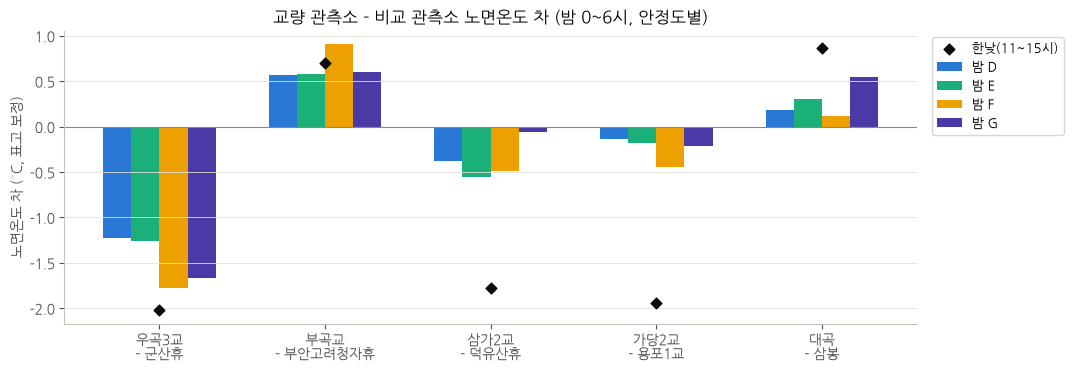

,교량(후보),비교 지점,거리(km),표고차(m),교량 거리(m),밤 평균차,밤에 더 차가운 비율,한낮 평균차,밤 D,밤 E,밤 F,밤 G,Ice 건수(교량/비교)
0,우곡3교(도),군산휴(도),4.67,-20.0,76.58,-1.60,0.98,-2.02,-1.23,-1.26,-1.78,-1.67,7 / 1
1,부곡교(도),부안고려청자휴(도),3.81,7.0,53.63,0.60,0.08,0.70,0.57,0.57,0.91,0.60,64 / 118
2,삼가2교(도),덕유산휴(도),8.82,-94.0,1.35,-0.14,0.50,-1.77,-0.38,-0.55,-0.49,-0.06,0 / 10
3,가당2교(도),용포1교(도),4.02,32.0,260.75,-0.21,0.62,-1.94,-0.13,-0.18,-0.45,-0.21,1 / 28
4,대곡(도),삼봉(도),1.59,45.0,8.66,0.48,0.20,0.86,0.18,0.31,0.12,0.54,1 / 0


In [8]:
BRIDGE_PAIRS = [(12409, 12103), (12410, 12210), (33410, 33103), (33409, 33206), (33412, 33411)]
night_t, noon_t = W.index.hour.isin(range(0, 7)), W.index.hour.isin(range(11, 16))
cls_t = stab["안정도"].reindex(W.index)
ice_cnt = rwis.groupby("stn")["ice"].sum()
rows = []
for b, r in BRIDGE_PAIRS:
    dz = elev_st[b] - elev_st[r]
    diff = W[b] - W[r] + 0.0065 * dz
    dn = diff[night_t]
    row = {"교량(후보)": st_info.loc[b, "지점명"], "비교 지점": st_info.loc[r, "지점명"], "거리(km)": D_all.loc[b, r],
           "표고차(m)": dz, "교량 거리(m)": rwis_pt.set_index("stn").loc[b, "고속도로 교량 거리(m)"],
           "밤 평균차": dn.mean(), "밤에 더 차가운 비율": (dn < 0).mean(), "한낮 평균차": diff[noon_t].mean()}
    for c in ["D", "E", "F", "G"]:
        row[f"밤 {c}"] = dn[cls_t[night_t] == c].mean()
    row["Ice 건수(교량/비교)"] = f"{ice_cnt[b]:.0f} / {ice_cnt[r]:.0f}"
    rows.append(row)
bridge_tbl = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(11, 3.8))
xs = np.arange(len(bridge_tbl))
for i, (c, color) in enumerate(zip(["D", "E", "F", "G"], [PALETTE[0], PALETTE[2], PALETTE[3], PALETTE[6]])):
    ax.bar(xs + (i - 1.5) * 0.17, bridge_tbl[f"밤 {c}"], width=0.17, color=color, label=f"밤 {c}")
ax.scatter(xs, bridge_tbl["한낮 평균차"], color=INK, marker="D", s=30, zorder=5, label="한낮(11~15시)")
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_xticks(xs, [f"{a.replace('(도)', '')}\n- {b.replace('(도)', '')}" for a, b in
                   zip(bridge_tbl["교량(후보)"], bridge_tbl["비교 지점"])])
ax.set_ylabel("노면온도 차 (°C, 표고 보정)")
ax.set_title("교량 관측소 - 비교 관측소 노면온도 차 (밤 0~6시, 안정도별)")
ax.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(axis="x", visible=False)
plt.show()
bridge_tbl.round(2)

고속도로 교량에서 10m 안에 있는 관측소는 삼가2교·대곡입니다. 부곡교·우곡3교는 50~80m, 가당2교·용포1교는 약 260m 떨어져 있습니다. 좌표 오차(수십 m)를 고려해도 이름만으로 교량 위라고 볼 수 없습니다.

우곡3교는 4.7km 떨어진 군산휴보다 밤 노면이 평균 1.6°C 낮고(밤의 98%) 안정할수록 차이가 커집니다(D -1.2°C, F -1.8°C). 선행연구의 교량 효과(1~2°C)와 맞습니다. Ice도 7건으로 군산휴(1건)보다 많습니다. 반대로 부곡교는 부안고려청자휴보다 밤에 0.6°C 따뜻하고(Ice 64건 vs 118건) 대곡도 삼봉보다 0.5°C 따뜻합니다. 산지의 삼가2교·가당2교는 밤에 0.1~0.2°C 낮고 한낮에 1.8~1.9°C 낮습니다.

교량 효과는 지점마다 달랐습니다(김유정 외 2023과 같은 결론, H8 부분 지지). 05-2에서는 교량 요인을 도로 요인 안에서만 가중했습니다.

### 13-8. 터널 (H9)

호남터널(23403) 관측소는 고속도로 터널에서 약 200m 떨어져 있습니다. 이웃 관측소(정읍휴, 고인돌휴)와 일변화, 10분 급변 횟수를 비교했습니다.

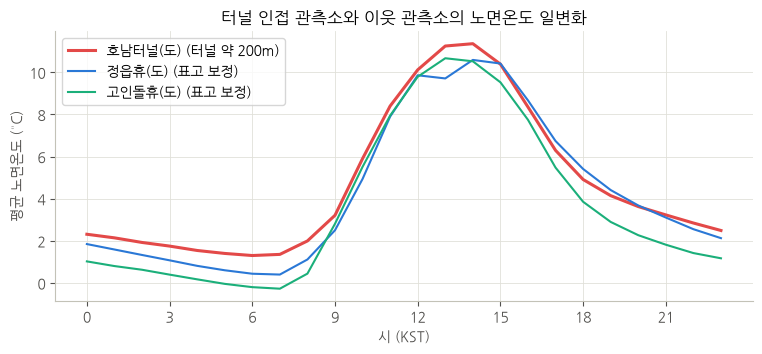

,10분 2°C 초과 변화(건),그중 낮(9~16시),일교차 평균,지점명,노선,고속도로 터널 거리(m)
stn,,,,,,
12103,324,314,15.3,군산휴(도),서해안,2811.7
12409,260,245,13.8,우곡3교(도),서해안,1568.4
33410,212,204,14.1,삼가2교(도),통영-대전중부선,1251.6
12211,196,143,13.8,고인돌휴(도),서해안,11268.2
12210,170,150,14.9,부안고려청자휴(도),서해안,23090.9
12410,157,146,14.9,부곡교(도),서해안,20489.0
33206,122,107,16.5,용포1교(도),통영-대전중부선,3684.9
33412,113,95,14.2,대곡(도),통영-대전중부선,407.2
23403,112,104,12.6,호남터널(도),호남선,206.1


In [9]:
tn, tn_nbrs = 23403, [23204, 12211]
diurnal_tn = W[[tn] + tn_nbrs].groupby(W.index.hour).mean()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(diurnal_tn.index, diurnal_tn[tn], color=PALETTE[7], linewidth=2.2, label=f"{st_info.loc[tn, '지점명']} (터널 약 200m)")
for s, color in zip(tn_nbrs, [PALETTE[0], PALETTE[2]]):
    ax.plot(diurnal_tn.index, diurnal_tn[s] - 0.0065 * (elev_st[tn] - elev_st[s]), color=color,
            label=f"{st_info.loc[s, '지점명']} (표고 보정)")
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("시 (KST)")
ax.set_ylabel("평균 노면온도 (°C)")
ax.set_title("터널 인접 관측소와 이웃 관측소의 노면온도 일변화")
ax.legend()
plt.show()
jump = W.diff().abs()
pd.DataFrame({
    "10분 2°C 초과 변화(건)": (jump > 2).sum(), "그중 낮(9~16시)": (jump[W.index.hour.isin(range(9, 17))] > 2).sum(),
    "일교차 평균": W.groupby(W.index.normalize()).agg(lambda s: s.max() - s.min()).mean(),
}).join(st_info[["지점명", "노선"]]).join(rwis_pt.set_index("stn")["고속도로 터널 거리(m)"]).sort_values(
    "10분 2°C 초과 변화(건)", ascending=False).round(1)

호남터널 관측소는 표고를 보정한 이웃 관측소보다 밤 노면이 0.5~1°C 따뜻하고 한낮 최고온도는 비슷합니다. 10분 사이 2°C 넘게 바뀐 횟수(112건)는 17개소 중 중간이고 대부분 낮에 해가 났다 가려질 때입니다.

김유정 외(2023)의 터널 입·출구 노면온도 급변은 이동관측으로 본 공간 변화입니다. 터널에서 200m 떨어진 고정 관측소 하나로는 확인할 수 없어서 판단을 보류했습니다(H9). 05-2의 터널 입출구 요인은 선행연구를 근거로 둡니다.

### 13-9. 노면상태 코드와 변수 영향 재검토 (H1, H11)

팀 사전 분석자료(노면상태별 변수 영향 분석)는 2024-11-01~20 자료로 코드표 없이 코드 의미를 추정했습니다. 공식 코드표와 비교하면 다음과 같습니다.

| 코드 | 분석자료의 추정 | 공식 정의 (데이터 설명자료) | 보정 |
|------|-----------------|------------------------------|------|
| 1 | 건조 | Dry | 같음 |
| 2 | 습윤 (비 젖음) | Wet | 같음 |
| 14 | 마르는 중 / 약습윤 | Damp (얇은 수막) | 수막 두께로 나눈 상태. 2에서 14, 1로 이어지는 전이는 마르는 과정과 맞음 |
| 12 | 결빙 주의 (비 없이 차가운 노면) | 수막 Damp 이상, 노면 1.5°C 미만, 제빙제로 결빙 안 됨 | 젖어 있지만 제빙제 때문에 얼지 않은 노면 |
| 13 | 결빙 가능성 | 수막 Damp 이상, 노면 1.5°C 미만, 제빙제 사용으로 결빙 시작 | 제빙제가 있어도 얼기 시작한 노면 |
| 0 | 미확인 / 센서 상태 | 코드표에 없음 | 미정의 값으로 처리 |

같은 효과크기(Kruskal-Wallis ε², Cliff's δ)를 기온·습도를 재는 9개소에서 기간별로 다시 계산했습니다. δ는 습윤(2)을 건조(1)와 비교한 값입니다.

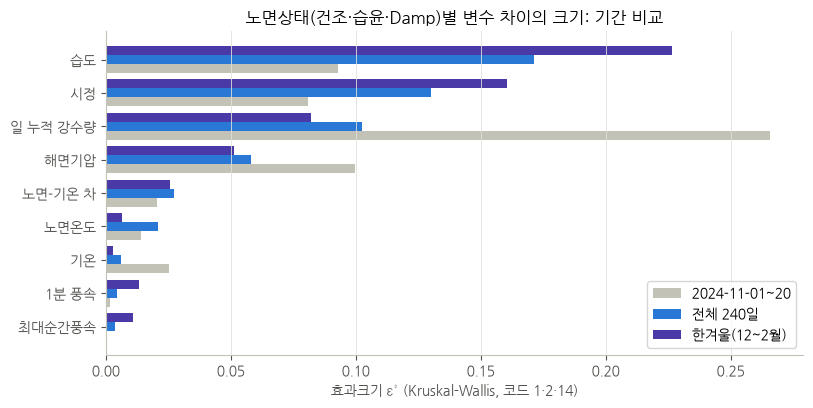

ε² (1·2·14)                    δ 습윤(2) vs 건조(1)                   
기간       2024-11-01~20 전체 240일 한겨울(12~2월)    2024-11-01~20 전체 240일 한겨울(12~2월)
변수                                                                           
습도               0.093   0.171      0.227            0.768   0.659      0.713
시정               0.081   0.130      0.161           -0.730  -0.589     -0.633
일 누적 강수량         0.266   0.102      0.082            0.703   0.306      0.252
해면기압             0.100   0.058      0.051           -0.757  -0.419     -0.361
노면-기온 차          0.020   0.027      0.026           -0.351  -0.243     -0.254
노면온도             0.014   0.021      0.006            0.237  -0.233     -0.138
기온               0.025   0.006      0.003            0.333  -0.132     -0.007
1분 풍속            0.002   0.004      0.013            0.110  -0.057     -0.128
최대순간풍속           0.001   0.004      0.011            0.072  -0.060     -0.132

In [10]:
OWN_VARS = {"일 누적 강수량 (mm)": "일 누적 강수량", "해면기압 (hPa)": "해면기압", "습도 (%)": "습도", "시정 (m)": "시정",
            "기온 (C)": "기온", "노면-기온": "노면-기온 차", "rst": "노면온도", "1분 풍속 (m/s)": "1분 풍속",
            "최대순간풍속 (m/s)": "최대순간풍속"}
o9 = m[m["ta"].notna()].copy()
for c in ["일 누적 강수량 (mm)", "해면기압 (hPa)", "습도 (%)", "시정 (m)", "기온 (C)"]:
    o9[c] = o9[c].where(o9[c] > -999)
for c in ["1분 풍속 (m/s)", "최대순간풍속 (m/s)"]:
    o9[c] = o9[c].where(o9[c].between(0, 60))
o9["노면-기온"] = o9["rst"] - o9["ta"]


def epsilon_squared(groups):
    """Kruskal-Wallis 효과크기 ε² = (H - k + 1) / (n - k)."""
    groups = [x.dropna().to_numpy() for x in groups if x.notna().sum() > 5]
    n, k = sum(len(x) for x in groups), len(groups)
    return (kruskal(*groups).statistic - k + 1) / (n - k)


def cliffs_delta(a, b, n_max=4000, seed=0):
    """Cliff's δ = P(a > b) - P(a < b). 표본이 크면 n_max개씩 뽑아 계산한다."""
    rng = np.random.default_rng(seed)
    a, b = a.dropna().to_numpy(), b.dropna().to_numpy()
    a = rng.choice(a, min(n_max, len(a)), replace=False)
    b = rng.choice(b, min(n_max, len(b)), replace=False)
    return np.sign(a[:, None] - b[None, :]).mean()


EFFECT_PERIODS = {"2024-11-01~20": o9["time"] < "2024-11-21", "전체 240일": o9["time"].notna(),
                  "한겨울(12~2월)": o9["time"].dt.month.isin([12, 1, 2])}
rows = []
for pname, pmask in EFFECT_PERIODS.items():
    s3 = o9[pmask & o9["state"].isin([1, 2, 14])]
    for col, name in OWN_VARS.items():
        rows.append({"기간": pname, "변수": name,
                     "ε²": epsilon_squared([s3.loc[s3["state"] == k, col] for k in [1, 2, 14]]),
                     "δ": cliffs_delta(s3.loc[s3["state"] == 2, col], s3.loc[s3["state"] == 1, col])})
eff = pd.DataFrame(rows)
eff_tbl = pd.concat([eff.pivot(index="변수", columns="기간", values="ε²"), eff.pivot(index="변수", columns="기간", values="δ")],
                    axis=1, keys=["ε² (1·2·14)", "δ 습윤(2) vs 건조(1)"])
eff_tbl = eff_tbl.reindex(columns=list(EFFECT_PERIODS), level=1).sort_values(("ε² (1·2·14)", "전체 240일"), ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.2))
order_v = eff_tbl.index[::-1]
for i, (pname, color) in enumerate(zip(EFFECT_PERIODS, ["#c3c2b7", PALETTE[0], PALETTE[6]])):
    ax.barh(np.arange(len(order_v)) + (i - 1) * 0.27, eff_tbl.loc[order_v, ("ε² (1·2·14)", pname)], height=0.27,
            color=color, label=pname)
ax.set_yticks(np.arange(len(order_v)), order_v)
ax.set_xlabel("효과크기 ε² (Kruskal-Wallis, 코드 1·2·14)")
ax.set_title("노면상태(건조·습윤·Damp)별 변수 차이의 크기: 기간 비교")
ax.legend()
ax.grid(axis="y", visible=False)
plt.show()
eff_tbl.round(3)

11월 1~20일 결과는 분석자료와 같습니다(강수 0.266, 기압 0.100, 습도 0.093, 시정 0.081). 전체 기간에서는 습도(0.171)와 시정(0.130)이 강수(0.102)보다 크고, 한겨울에는 습도 0.227, 강수 0.082입니다. 일 누적 강수량은 그날 자정까지 남는 값이라 비가 그친 뒤 노면이 마른 시간에도 0보다 큽니다.

기온은 방향이 바뀝니다. 11월에는 젖은 노면일 때 기온이 높고(δ +0.33) 전체 기간에는 약간 낮으며(-0.13) 한겨울에는 차이가 없습니다(-0.01). 노면온도도 +0.24에서 -0.23으로 바뀝니다. 풍속은 모든 기간에서 노면상태와 거의 관계가 없습니다(ε² 0.013 이하, H11 지지). 바람은 대기 안정도를 거쳐 노면온도 분포에는 영향을 줍니다(13-5).

노면이 1.5°C 미만일 때 결빙관련 상태(3·4·13·15)와 그 밖의 상태도 비교했습니다.

In [11]:
cold_o9 = o9[(o9["rst"] < 1.5) & o9["state"].notna()]
rel_o9 = cold_o9["state"].isin([3, 4, 13, 15])
print(f"노면 1.5°C 미만 {len(cold_o9):,}건 중 결빙관련 {rel_o9.sum():,}건")
pd.Series({name: cliffs_delta(cold_o9.loc[rel_o9, col], cold_o9.loc[~rel_o9, col]) for col, name in OWN_VARS.items()},
          name="δ (결빙관련 vs 그 외)").sort_values().round(2).to_frame()

노면 1.5°C 미만 109,865건 중 결빙관련 3,672건


,δ (결빙관련 vs 그 외)
시정,-0.76
해면기압,-0.45
노면온도,-0.10
기온,-0.08
노면-기온 차,0.01
최대순간풍속,0.08
1분 풍속,0.10
일 누적 강수량,0.49
습도,0.68


In [12]:
c12 = m[m["state"] == 12]
pd.Series({
    "관측수": len(c12), "관측 지점 수": c12["stn"].nunique(), "노면온도 중앙값(°C)": c12["rst"].median(),
    "노면 1.5°C 미만 비율": (c12["rst"] < 1.5).mean(), "강수 중 비율": (c12["aws_rain"] >= 1).mean(),
    "최근 12시간 강수 비율": (c12["강수시간12h"] > 0).mean(), "ASOS 적설 있음 비율": (c12["snow"] > 0).mean(),
    "최근접 AWS 습도 중앙값(%)": c12["aws_rh"].median(), "밤(18~08시) 비율": (~c12["hour"].between(9, 17)).mean(),
}, name="코드 12 (전체 기간)").round(3).to_frame()

,코드 12 (전체 기간)
관측수,15002.000
관측 지점 수,6.000
노면온도 중앙값(°C),-1.300
노면 1.5°C 미만 비율,0.980
강수 중 비율,0.131
최근 12시간 강수 비율,0.591
ASOS 적설 있음 비율,0.450
최근접 AWS 습도 중앙값(%),76.800
밤(18~08시) 비율,0.904


노면이 1.5°C 미만일 때 결빙관련 상태를 가르는 변수는 시정(δ -0.76), 습도(+0.68), 강수(+0.49), 해면기압(-0.45)입니다. 노면온도(-0.10)와 기온(-0.08)은 차이가 거의 없습니다(H1 지지).

코드 12는 전체 기간에 1만 5천 건이고 서해안선 6개소에서 주로 밤(90%)에 나옵니다. 노면온도 중앙값은 -1.3°C이고 59%는 최근 12시간 안에 강수가 있었으며 45%는 적설 중입니다. 공식 정의대로 수막이 있지만 제빙제 때문에 얼지 않은 노면으로 봤습니다. 최근 강수가 없는 41%는 미리 뿌린 염수로 젖은 노면일 수 있습니다.

같은 기상이라도 제설·제빙 작업 여부에 따라 노면상태가 Ice 대신 12로 나올 수 있습니다. 기상 자료로 설명할 수 없는 부분이고 노선 간 Ice 빈도를 비교할 때 주의해야 합니다(5-2).

### 13-10. ASOS 지면온도는 노면온도를 대신할 수 있는가 (H10)

나정호 외(2021)는 ASOS 지면온도가 실제 노면온도가 아니어서 결빙 예측에 도움이 되지 않았다고 봤습니다. 최근접 ASOS의 지면온도와 기온을 RWIS 노면온도와 1시간 간격으로 비교했습니다.

In [13]:
asos_idx = asos.set_index(["stn", "time"])
hr = m[m["time"].dt.minute == 0][["stn", "time", "hour", "rst", "asos_stn"]].copy()
key = list(zip(hr["asos_stn"], hr["time"]))
hr["지면온도"] = asos_idx["지면온도(°C)"].reindex(key).to_numpy()
hr["ASOS 기온"] = asos_idx["기온(°C)"].reindex(key).to_numpy()
hr = hr.dropna(subset=["rst", "지면온도", "ASOS 기온"])
rows = []
for name, sub in [("전체", hr), ("밤 (0~6시)", hr[hr["hour"] <= 6]), ("한낮 (11~15시)", hr[hr["hour"].between(11, 15)])]:
    for proxy in ["지면온도", "ASOS 기온"]:
        err = sub[proxy] - sub["rst"]
        rows.append({"시간대": name, "대리 변수": proxy, "상관": sub[proxy].corr(sub["rst"]), "BIAS": err.mean(),
                     "RMSE": np.sqrt((err ** 2).mean()), "영하 여부 일치율": ((sub[proxy] <= 0) == (sub["rst"] <= 0)).mean()})
pd.DataFrame(rows).set_index(["시간대", "대리 변수"]).round(3)

상관   BIAS   RMSE  영하 여부 일치율
시간대         대리 변수                                  
전체          지면온도     0.898 -0.443  3.018      0.859
            ASOS 기온  0.920 -1.698  3.156      0.882
밤 (0~6시)    지면온도     0.902  0.423  2.438      0.834
            ASOS 기온  0.942 -0.799  2.122      0.894
한낮 (11~15시) 지면온도     0.818 -1.543  4.303      0.938
            ASOS 기온  0.862 -4.110  5.284      0.865

지면온도와 기온 모두 노면온도와 상관이 0.82~0.94이고 RMSE가 2~5°C입니다. 그대로 노면온도로 쓸 수는 없습니다(H10 지지). 한낮에는 지면온도가 기온보다 노면에 가깝고(RMSE 4.3 vs 5.3°C, 영하 여부 일치 94% vs 87%) 밤에는 기온이 더 가깝습니다(RMSE 2.1 vs 2.4°C). 낮의 일사 정보가 있어서 03에서는 보간 지면온도(`tg`)를 보조 입력으로 썼습니다.

## 14. 정리: 주요 발견과 분석 방향

### 14-1. 자료 특성

| 구분 | 발견 | 근거 | 반영 |
|------|------|------|------|
| 파일 | 240일 x 4종, 컬럼·날짜 일관 | 1장 | 일별 파일 병합 |
| 결측 표기 | RWIS -999, AWS -99.x(여러 코드), ASOS 빈칸 | 3-2 | 자료별로 NaN 통일 (02) |
| 센서 고착 | 여산휴 노면온도·상태가 27일간 10.7°C·Dry로 고정 | 3-4 | 6시간 이상 같은 값이면 결측 처리 (02) |
| 이상값 | 풍속 100 m/s, 기압 이상값 일부 | 3-3 | 물리 범위 밖은 NaN (02) |
| 시각 | RWIS·AWS·ASOS 모두 KST로 정렬 | 3-5 | 그대로 결합 |
| 관측소 구성 | 거점 2, 기본 7, 목표(결빙) 8. 목표 관측소는 노면상태·노면온도만 | 2-1, 3-2 | 추정 대상은 노면온도, 기상은 AWS·ASOS 보간 (02, 03) |
| DEM | 값이 0~0.89로 정규화 (x 약 1,956 = m), 저지대 20m 계단 | 2-2 | 미터로 환산 (02) |
| 기온감률 | 지역 감률 -0.6 ~ -0.7°C/100m, 지역 규모 역전 드묾. 산 정상(설천봉)만 안정한 밤에 역전층 위 | 8장, 13-5 | 0.65°C/100m 고도 보정 (02). 산 정상·섬 AWS 제외는 6장과 13장의 비교에만 적용하고, 02의 IDW는 34개소를 모두 씀 |
| 최근접 AWS | 삼가2교의 최근접 AWS가 설천봉(표고차 1,100m) | 2-4 | 고도 보정한 IDW 사용 (02) |
| 노면온도 일변화 | 7시 최저, 13~14시 최고, 낮 지점 차가 큼 | 4-2 | 일사·그늘 변수 (02), 낮 오차 큼 (03) |
| 야간 냉각 | 맑은 밤 -7°C, 흐린 밤 -3.5°C | 4-3 | 운량·일조 변수 (02) |
| 공간 상관 | 5km 안 RMSE 1~1.5°C, 20km 넘으면 2°C 이상 | 4-7 | 주변 RWIS IDW 변수 (02, 03) |
| 검증 지점 | 모두 4km 안에 상관 0.99 이웃, Ice는 부곡교만 | 10장 | 교차검증과 검증 지점 성능을 함께 제시 (03, 04) |
| Ice 희소·간헐 | 303건(0.05%), 대부분 10분 1회, 10분 뒤 유지 10% | 5장 | 결빙관련 상태로 학습, 평가 한계 명시 (04) |
| 센서 판정 | 결빙 계열 상태는 노면 1.5°C 미만에서만 나옴. 제빙 코드(12, 13)는 서해안선만 | 5-2, 13-1, 13-9 | 노선·지점 간 Ice 비교 시 주의 (05) |
| 결빙 조건 | Ice의 88%가 최근 12h 강수, 73%가 적설 중, 서리 조건 7% | 6-2 | 강수·적설·습도 변수, 결빙 가능 조건 (02, 05) |
| 두 겨울 | 기온 비슷, 강설은 2024-25가 2배, Ice는 3.2배 | 7-2 | 위험도의 기상 요인은 저온 + 수분 (05) |
| 풍향 | 내륙 노선 Ice는 서·북서풍(서해 강설) | 6-3 | 강설 패턴 해석 근거 |
| 표고 | 표고가 높을수록 노면 영하 비율이 높음 | 4-6 | 지형 위험 요인 (05) |
| 안개 | 시정 2곳뿐, 산지에서 저시정 잦음 | 12장 | 변수로 쓰지 않음 |

### 14-2. 이론 검증 결과

| 가설 | 결과 | 근거 | 반영 |
|------|------|------|------|
| H1 수분 공급이 결빙의 전제 | 지지 | 노면 1.5°C 미만에서 Ice 비율이 강수 중 10.7‰, 무강수 0.3‰. Ice의 81%가 강수 중·직후 3시간 이내. 1.5°C 아래에서 결빙관련 상태를 가르는 변수는 시정·습도·강수(δ 0.5~0.8), 온도는 δ 0.1 | 결빙 가능 조건 = 저온 + 습도 + 수분 공급 (05) |
| H2 Bonanno 기준 (강수 시 1°C, 무강수 시 0°C) | 부분 지지 | 강수 중 Ice의 93%가 노면 < 1°C. 무강수 Ice는 62%만 ≤ 0°C (센서 경계 1.5°C) | 05-1의 임계값(Ice P90 = 1.0°C)이 Bonanno의 1°C와 일치 |
| H3 서리 조건 | 조건은 재현, Ice 라벨과는 다름 | 서리 조건은 기온·습도 동시 상승 시 52%(그 외 9%). 서리 조건의 0.35%만 Ice, 44%는 Dry | 서리는 수분 공급 조건 중 하나로만 사용 |
| H4 융해·재결빙이 가장 흔함 | 부분 지지 | Ice의 97%가 24시간 내 영상 노면, 71%가 적설 중, 강수와 겹치지 않는 경우는 8% | 하루 0°C 교차가 많을수록 Ice일 증가 (0.9%, 9.7%) |
| H5 복사냉각 | 냉각은 지지, 결빙과는 반대 | 맑은 밤 -7°C vs 흐린 밤 -3.5°C. Ice 비율은 바람·구름 있는 밤(D 5.4‰)이 고요한 밤(G 0.8‰)보다 높음 | 운량은 노면온도 추정 변수로 사용 |
| H6 안정도와 감률·공간 변동 | 부분 지지 | 표고 설명력 D -0.92, F -0.57, 잔차 0.45°C, 0.79°C. 감률은 산 정상을 넣을 때만 G에서 완만 | 고정 감률 유지, 안정한 밤의 추정 오차가 크다는 점 명시 (03) |
| H7 하늘시계·차폐 | 하늘시계 검증 불가, 차폐 지지 | DEM SVF 0.94~1.00, 밤 잔차와 무관. 지형 그늘과 맑은 한낮 노면 편차 순위상관 -0.38 | 지형 그늘(`shade_winter`) 사용 (02, 05) |
| H8 교량 1~2°C 차가움 | 지점마다 다름 | 우곡3교 -1.6°C(안정할수록 큼), 부곡교 +0.6°C, 대곡 +0.5°C, 산지 교량은 밤 -0.1~-0.2°C·한낮 -1.8°C | 교량 요인을 도로 요인 안에서만 가중 (05) |
| H9 터널 입출구 급변 | 판단 보류 | 터널에서 200m 떨어진 고정 관측소 1곳뿐, 급변 횟수는 중간 | 터널 입출구 요인은 선행연구 근거 (05) |
| H10 ASOS 지면온도 | 지지 | 노면온도 대비 RMSE 2.4~4.3°C. 한낮에는 기온보다 노면에 가까움 | 보조 입력으로만 사용 (03) |
| H11 젖은 노면과 변수 | 기간에 따라 다름 | 11월 강수 ε² 0.27, 한겨울 0.08, 습도 0.09, 0.23. 기온 방향은 11월만 양(+). 풍속은 항상 무관 | 습도·강수·적설 중심, 늦가을 자료만으로 일반화하지 않음 |

### 14-3. 분석 방향

탐색 결과로 뒤 단계의 방향을 정했습니다.

노면센서는 1.5°C 미만에서만 결빙 계열 상태를 판정합니다. 그래서 노면온도로 결빙 가능 여부를 보고 강수, 적설, 습도로 실제 결빙 여부를 보는 구조로 잡았습니다. 04의 분류와 05-1의 결빙 가능 조건이 이 구조입니다.

전북 고속도로의 Ice는 81%가 강설 중이거나 강수 직후입니다. 서리형(Jang 2024)은 1% 미만, 순수 융해·재결빙형은 8%입니다. 사전 검토에서 꼽은 서리 조건, 냉각 속도, 일출 시각은 이 자료의 Ice와 관계가 약했습니다.

노면온도 추정은 안정한 밤과 맑은 낮에 어렵습니다. 이때 지점 고유의 국지 요인이 커지는데 관측소가 17곳뿐입니다. 지리 변수는 물리적 의미가 분명한 것(표고, 지형 그늘, 지형 상대고도, 하천·교량·터널 거리)으로 제한했습니다.

라벨에는 제설·제빙 작업의 영향이 섞여 있습니다(코드 12·13). 10분 단위 Ice를 기상만으로 맞히기 어려워서 04에서는 결빙관련 상태로 넓혀 학습했습니다.

선행연구의 정확도(95%)는 라벨(물리 기준, VMS 메시지)과 검증 방식(무작위 분할)이 달라서 이 과제의 성능과 직접 비교할 수 없습니다.